### **Harmonization of MRI related metrics across ABCD sites, and between studies.**

Using Clinical-ComBAT [1] which leverages non-linear methods to harmonize data to a reference site.
This notebook will perform harmonization for sMRI and rs-fMRI features. dMRI data were already harmonized using
RISH features [2] and therefore are not harmonized again here.

**References**

[1] Girard, G., Edde, M., Dumais, F., David, Y., Dumont, M., Theaud, G., Houde, J.-C., Boré, A., Descoteaux, M., & Jodoin, P.-M. (2025). Clinical-ComBAT: A diffusion-weighted MRI harmonization method for clinical applications (arXiv:2511.04871). arXiv. https://doi.org/10.48550/arXiv.2511.04871

[2] Cetin-Karayumak, S., Zhang, F., Zurrin, R., Billah, T., Zekelman, L., Makris, N., Pieper, S., O’Donnell, L. J., & Rathi, Y. (2024). Harmonized diffusion MRI data and white matter measures from the Adolescent Brain Cognitive Development Study. Scientific Data, 11(1), 249. https://doi.org/10.1038/s41597-024-03058-w


In [1]:
# Imports
import os
import pathlib
import subprocess

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import ConnectionPatch
import numpy as np
import scipy
import seaborn as sns
from tqdm import tqdm

In [2]:
# Setting up data and output paths.
repository_dir = "~/code/Gagnon_BrainProfilesAssociations/"
data_abcd = "/Volumes/T7/BrainProfilesAssociations/ABCD/"
data_geste = "/Volumes/T7/BrainProfilesAssociations/GESTE/"
data_banda = "/Volumes/T7/BrainProfilesAssociations/BANDA/"
output_folder = "/Volumes/T7/BrainProfilesAssociations/"

# Create output folder if it doesn't exist.
output_dir = f"{output_folder}/Harmonization/"
os.makedirs(output_dir, exist_ok=True)

In [3]:
# Load the atlas description to get the region names.
atlas = pd.read_csv(f"{repository_dir}/atlas/atlas-BrainnetomeChild/atlas-BrainnetomeChild_dseg.tsv", sep="\t")

# Replace BRAIN_STEM, CEREBELLUM_LEFT, and CEREBELLUM_RIGHT in the label column by brainstem, left_cerebellum_cortex, and right_cerebellum_cortex.
atlas["label"] = atlas["label"].replace({"BRAIN_STEM": "brainstem", "CEREBELLUM_LEFT": "left_cerebellum_cortex", "CEREBELLUM_RIGHT": "right_cerebellum_cortex"})

In [4]:
# Fetch Harding font.
font_files = []
for fontpath in font_manager.findSystemFonts(fontpaths=None, fontext='ttf'):
    if "Arial".lower() in fontpath.lower():
        font_files.append(fontpath)
for font_file in font_files:
    font_manager.fontManager.addfont(font_file)

# Set Harding font.
plt.rcParams['font.family'] = 'Arial'

In [5]:
# Fetch the site distribution for the ABCD dataset.
demo_df = pd.read_csv(f"{output_folder}/abcd_demo.csv")
included_subs = demo_df["subjectkey"].tolist()

# Using the site16 as the reference site, we will harmonize the other sites to it.
# First, fetch the anatomical data for the ABCD dataset.
subcortical_vol_data = pd.read_csv(f"{output_folder}/QC/ABCD_subcortical_volumes_QCed.csv")
rh_cortical_vol_data = pd.read_csv(f"{output_folder}/QC/ABCD_right_cortical_volume_QCed.csv")
lh_cortical_vol_data = pd.read_csv(f"{output_folder}/QC/ABCD_left_cortical_volume_QCed.csv")

# Keep only the included subjects.
subcortical_vol_data = subcortical_vol_data[subcortical_vol_data["subjectkey"].isin(included_subs)].sort_values(by="subjectkey")
rh_cortical_vol_data = rh_cortical_vol_data[rh_cortical_vol_data["subjectkey"].isin(included_subs)].sort_values(by="subjectkey")
lh_cortical_vol_data = lh_cortical_vol_data[lh_cortical_vol_data["subjectkey"].isin(included_subs)].sort_values(by="subjectkey")

# Assert the number of subjects is the same across datasets.
assert len(subcortical_vol_data) == len(rh_cortical_vol_data), "Number of subjects in subcortical and right cortical volume data do not match."
assert len(subcortical_vol_data) == len(lh_cortical_vol_data), "Number of subjects in subcortical and left cortical volume data do not match."

# Assert subjectkey columns are identical across datasets.
assert all([a == b for a, b in zip(rh_cortical_vol_data["subjectkey"], lh_cortical_vol_data["subjectkey"])]), "Subject keys do not match between subcortical and right cortical volume data."
assert all([a == b for a, b in zip(subcortical_vol_data["subjectkey"], lh_cortical_vol_data["subjectkey"])]), "Subject keys do not match between subcortical and left cortical volume data."
assert all([a == b for a, b in zip(subcortical_vol_data["subjectkey"], demo_df["subjectkey"])]), "Subject keys do not match between subcortical volume data and ABCD data."

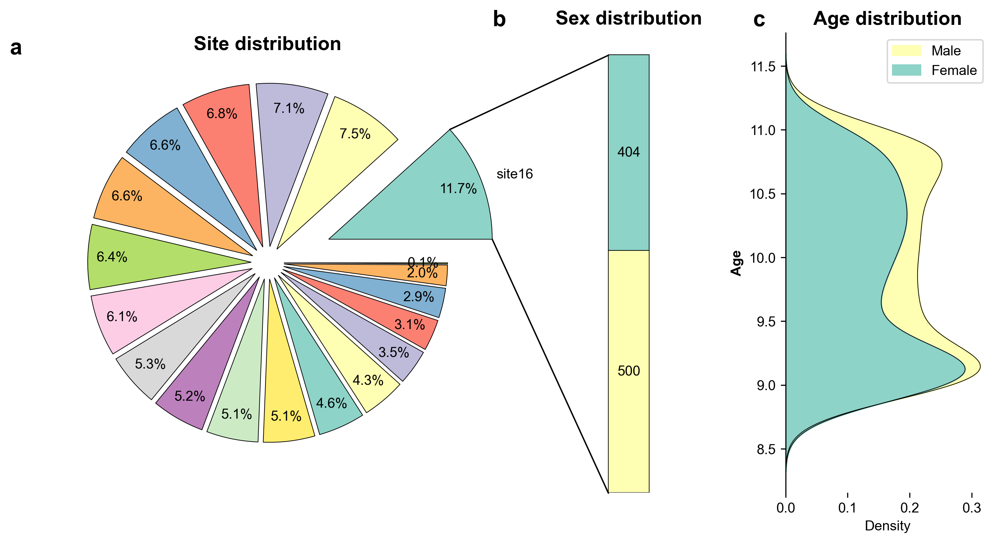

In [24]:
# Create a bar of pie chart for the site distribution, using site16 as the site column.
# First, create the colormap from set3 palette.
cmap = sns.color_palette("Set3", len(demo_df.site_id.unique()))

# Creata a bar of pie chart for the site distribution.
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 6),
                                    gridspec_kw={"width_ratios": [2, 1, 1], "height_ratios": [1]}, dpi=300)

# Calculate the ratio of each site.
site_counts = demo_df["site_id"].value_counts()
site_counts = site_counts[site_counts > 0]
site_counts = site_counts / site_counts.sum() * 100

overall_ratios = site_counts.values
overall_labels = ["site16"] + [""] * (len(site_counts.index) - 1)
explode = [0.4] + [0.1] * (len(overall_ratios) - 1)
wedges, *_ = ax1.pie(overall_ratios, autopct='%1.1f%%', explode=explode,
                     colors=cmap, labels=overall_labels,
                     pctdistance=0.85,
                     wedgeprops={"linewidth": 0.5, "edgecolor": "black"},)

# Bar charts params.
sex_count = demo_df[demo_df["site_id"] == "site16"].sex.value_counts()
sex_ratio = sex_count.values
sex_labels = ["Male", "Female"]
bottom = 1
width = 0.2

# Set title for pie chart.
ax1.set_title("Site distribution", fontdict={"fontsize": 14, "weight": "bold"})

# colormap for bar and density plots.
set2 = sns.color_palette("Set3")

for j, (height, label) in enumerate(reversed([*zip(sex_ratio, sex_labels)])):
    bottom -= height
    bc = ax2.bar(0, height, width, bottom=bottom, color=set2[j], label=label,
                 alpha=1, edgecolor="black", linewidth=0.5)
    ax2.bar_label(bc, label_type='center')

# Set the title and labels.
ax2.set_title("Sex distribution", fontdict={"fontsize": 14, "weight": "bold"})
ax2.axis("off")
ax2.set_xlim(- 2.5 * width, 2.5 * width)

# use ConnectionPatch to draw lines between the pie and bar charts.
theta1, theta2 = wedges[0].theta1, wedges[0].theta2
center, r = wedges[0].center, wedges[0].r
bar_height = sum(sex_ratio)

# Draw the connection lines.
x = r * np.cos(np.pi / 180 * theta2) + center[0]
y = r * np.sin(np.pi / 180 * theta2) + center[1]
con = ConnectionPatch(xyA=(-width / 2, 0), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color("black")
con.set_linewidth(1)
ax2.add_artist(con)

# Bottom line.
x = r * np.cos(np.pi / 180 * theta1) + center[0]
y = r * np.sin(np.pi / 180 * theta1) + center[1]
con = ConnectionPatch(xyA=(-width / 2, -bar_height), coordsA=ax2.transData,
                      xyB=(x, y), coordsB=ax1.transData)
con.set_color("black")
con.set_linewidth(1)
ax2.add_artist(con)

# Add age distribution as a density plot, stratified by sex.
sns.kdeplot(data=demo_df[demo_df["site_id"] == "site16"], y="age",
            hue="sex", hue_order=[2, 1], ax=ax3, fill=True, palette=[set2[0], set2[1]],
            alpha=1, linewidth=1, multiple="layer")
sns.kdeplot(data=demo_df[demo_df["site_id"] == "site16"], y="age",
            hue="sex", hue_order=[2, 1], ax=ax3, fill=False, palette=["black", "black"],
            alpha=1, linewidth=0.5, multiple="layer", legend=False, zorder=2)
ax3.set_title("Age distribution", fontdict={"fontsize": 14, "weight": "bold"})
ax3.set_ylabel("Age", fontdict={"fontsize": 10, "weight": "bold"})
ax3.spines[["top", "right", "bottom"]].set_visible(False)
ax3.legend(["Male", "Female"], title="")

# Add a, b, c labels to the subplots.
for i, ax in enumerate([ax1, ax2, ax3]):
    ax.text(-0.1, 1.05, f"{chr(97 + i)}", transform=ax.transAxes,
            fontsize=16, fontweight="bold", va="top", ha="right")


plt.show()

In [25]:
# Creating the sMRI matrix, intertwining the subcortical and cortical data.
cols = [item for pair in zip(lh_cortical_vol_data.columns[1:], rh_cortical_vol_data.columns[1:]) for item in pair]
cols.extend(subcortical_vol_data.columns[1:])

# Assert subject IDs are identical in the three sMRI df.
assert all([a == b for a, b in zip(rh_cortical_vol_data["subjectkey"], lh_cortical_vol_data["subjectkey"])]), "Subject IDs are not identical in the right and left cortical volume dataframes."
assert all([a == b for a, b in zip(rh_cortical_vol_data["subjectkey"], subcortical_vol_data["subjectkey"])]), "Subject IDs are not identical in the right cortical volume and subcortical volume dataframes."

# Convert each row of the sMRI data into a column.
abcd_vol_data = pd.DataFrame(columns=subcortical_vol_data["subjectkey"], index=cols)
for row in range(subcortical_vol_data.shape[0]):
    data = [item for pair in zip(lh_cortical_vol_data.iloc[row, 1:], rh_cortical_vol_data.iloc[row, 1:]) for item in pair]
    data.extend(subcortical_vol_data.iloc[row, 1:])
    abcd_vol_data[subcortical_vol_data.iloc[row, 0]] = data

# Assert that the first column is equal to the atlas labels.
assert all([a == b for a, b in zip(abcd_vol_data.index, atlas["label"])]), "Atlas labels are not equal to the first column of the sMRI data."

In [26]:
def create_harmonization_df(smri, demo, metric):
    """
    Create a harmonization dataframe from the ABCD dataset.
    """
    # Create a list of list to store the data.
    records = []

    # Loop over each subject.
    for s, sub in enumerate(tqdm(smri.columns, desc="Formatting data for harmonization")):

        # Get smri data for the subject.
        smri_data = smri.loc[:, sub].values

        # Get the demographic data for the subject.
        site = demo.loc[demo["subjectkey"] == sub, "site_id"].values[0]
        age = demo.loc[demo["subjectkey"] == sub, "age"].values[0]
        handedness = 1
        sex = demo.loc[demo["subjectkey"] ==  sub, "sex"].values[0]

        for i, region in enumerate(smri.index):
            records.append([sub, region, smri_data[i], metric, site, age, handedness, sex, 'HC'])
        
    return pd.DataFrame(records, columns=['sid', 'bundle', 'mean', 'metric', 'site', 'age', 'handedness', 'sex', 'disease'])

# Create the harmonization dataframe.
abcd_harmonization_vol_df = create_harmonization_df(abcd_vol_data, demo_df, "volume")

# Drop rows where sex == 3. (only 2 subjects)
abcd_harmonization_vol_df = abcd_harmonization_vol_df[abcd_harmonization_vol_df["sex"] != 3]

Formatting data for harmonization: 100%|██████████| 7709/7709 [00:10<00:00, 770.80it/s]


In [47]:
# Iterate over sites and save the data as a csv file.
os.makedirs(f"{output_folder}/Harmonization/Volume", exist_ok=True)
for site in tqdm(abcd_harmonization_vol_df["site"].unique(), desc="Saving harmonization data"):
    site_data = abcd_harmonization_vol_df[abcd_harmonization_vol_df["site"] == site]
    site_data.to_csv(f"{output_folder}/Harmonization/Volume/ABCD_harmonization_vol_{site}.csv", index=False)

Saving harmonization data: 100%|██████████| 19/19 [00:06<00:00,  2.87it/s]


In [48]:
# Save the sites in a text file.
with open(f"{output_folder}/Harmonization/ABCD_harmonization_sites.txt", "w") as f:
    for site in abcd_harmonization_vol_df["site"].unique():
        f.write(f"{site}\n")

In [55]:
# ** This is a long running process, go get a coffee! **
for site in tqdm(abcd_harmonization_vol_df["site"].unique(), "Running harmonization"):
    if site == "site16":
        continue
    # Run the harmonization.
    subprocess.run(["combat_fit",
                    f"{output_folder}/Harmonization/Volume/ABCD_harmonization_vol_site16.csv",
                    f"{output_folder}/Harmonization/Volume/ABCD_harmonization_vol_{site}.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Volume/",
                    "--ignore_handedness", "-m", "clinical", "-f"],
                    capture_output=False, check=True)
    # Apply the model to the moving site.
    subprocess.run(["combat_apply",
                    f"{output_folder}/Harmonization/Volume/ABCD_harmonization_vol_{site}.csv",
                    f"{output_folder}/Harmonization/Volume/{site}-site16.volume.clinical.model.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Volume/", "-f"],
                    capture_output=False, check=True)

Running harmonization: 100%|██████████| 19/19 [02:34<00:00,  8.14s/it]


In [56]:
# Load the thickness data.
lh_cortical_thickness_data = pd.read_csv(f"{output_folder}/QC/ABCD_left_cortical_thickness_QCed.csv")
rh_cortical_thickness_data = pd.read_csv(f"{output_folder}/QC/ABCD_right_cortical_thickness_QCed.csv")

# Filter for common subjects.
lh_cortical_thickness_data = lh_cortical_thickness_data[lh_cortical_thickness_data["subjectkey"].isin(included_subs)]
lh_cortical_thickness_data.sort_values(by="subjectkey", inplace=True)
rh_cortical_thickness_data = rh_cortical_thickness_data[rh_cortical_thickness_data["subjectkey"].isin(included_subs)]
rh_cortical_thickness_data.sort_values(by="subjectkey", inplace=True)

# Assert subjectkey columns are identical across datasets.
assert all([a == b for a, b in zip(rh_cortical_thickness_data["subjectkey"], lh_cortical_thickness_data["subjectkey"])]), "Subject keys do not match between left and right cortical thickness data."
assert all([a == b for a, b in zip(lh_cortical_thickness_data["subjectkey"], demo_df["subjectkey"])]), "Subject keys do not match between left cortical thickness data and ABCD data."

In [57]:
# Prepare the harmonized data for thickness and area.
# Creating the sMRI matrix, intertwining the cortical data.
cols = [item for pair in zip(lh_cortical_thickness_data.columns[1:], rh_cortical_thickness_data.columns[1:]) for item in pair]

# Assert subject IDs are identical in the three sMRI df.
assert all([a == b for a, b in zip(rh_cortical_vol_data["subjectkey"], lh_cortical_vol_data["subjectkey"])]), "Subject IDs are not identical in the right and left cortical volume dataframes."

# Convert each row of the sMRI data into a column.
abcd_thickness_data = pd.DataFrame(columns=lh_cortical_thickness_data["subjectkey"], index=cols)
for row in range(lh_cortical_thickness_data.shape[0]):
    data = [item for pair in zip(lh_cortical_thickness_data.iloc[row, 1:], rh_cortical_thickness_data.iloc[row, 1:]) for item in pair]
    abcd_thickness_data[lh_cortical_thickness_data.iloc[row, 0]] = data

# Assert that the first column is equal to the atlas labels.
assert all([a == b for a, b in zip(abcd_vol_data.index, atlas["label"][:188])]), "Atlas labels are not equal to the first column of the sMRI data."

In [58]:
abcd_harmonization_thickness_df = create_harmonization_df(abcd_thickness_data, demo_df, "thickness")

Formatting data for harmonization: 100%|██████████| 7709/7709 [00:12<00:00, 633.06it/s]


In [59]:
# Iterate over sites and save the data as a csv file.
os.makedirs(f"{output_folder}/Harmonization/Thickness", exist_ok=True)
for site in tqdm(abcd_harmonization_thickness_df["site"].unique(), desc="Saving harmonization data"):
    site_data = abcd_harmonization_thickness_df[abcd_harmonization_thickness_df["site"] == site]
    site_data.to_csv(f"{output_folder}/Harmonization/Thickness/ABCD_harmonization_thickness_{site}.csv", index=False)

Saving harmonization data: 100%|██████████| 19/19 [00:06<00:00,  2.91it/s]


In [60]:
# ** This is a long running process, go get a coffee! **
for site in tqdm(abcd_harmonization_thickness_df["site"].unique(), "Running harmonization"):
    if site == "site16":
        continue
    # Run the harmonization.
    subprocess.run(["combat_fit",
                    f"{output_folder}/Harmonization/Thickness/ABCD_harmonization_thickness_site16.csv",
                    f"{output_folder}/Harmonization/Thickness/ABCD_harmonization_thickness_{site}.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Thickness/",
                    "--ignore_handedness", "-m", "clinical", "-f"],
                    capture_output=False, check=True)
    subprocess.run(["combat_apply",
                    f"{output_folder}/Harmonization/Thickness/ABCD_harmonization_thickness_{site}.csv",
                    f"{output_folder}/Harmonization/Thickness/{site}-site16.thickness.clinical.model.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Thickness/", "-f"],
                    capture_output=False, check=True)

Running harmonization: 100%|██████████| 19/19 [02:09<00:00,  6.82s/it]


In [61]:
# Load the area data.
lh_cortical_area_data = pd.read_csv(f"{output_folder}/QC/ABCD_left_cortical_area_QCed.csv")
rh_cortical_area_data = pd.read_csv(f"{output_folder}/QC/ABCD_right_cortical_area_QCed.csv")

# Filter for common subjects.
lh_cortical_area_data = lh_cortical_area_data[lh_cortical_area_data["subjectkey"].isin(included_subs)]
lh_cortical_area_data.sort_values(by="subjectkey", inplace=True)
rh_cortical_area_data = rh_cortical_area_data[rh_cortical_area_data["subjectkey"].isin(included_subs)]
rh_cortical_area_data.sort_values(by="subjectkey", inplace=True)

# Assert subjectkey columns are identical across datasets.
assert all([a == b for a, b in zip(rh_cortical_area_data["subjectkey"], lh_cortical_area_data["subjectkey"])]), "Subject keys do not match between left and right cortical area data."
assert all([a == b for a, b in zip(lh_cortical_area_data["subjectkey"], demo_df["subjectkey"])]), "Subject keys do not match between left cortical area data and ABCD data."

In [62]:
# Prepare the harmonized data for area and area.
# Creating the sMRI matrix, intertwining the cortical data.
cols = [item for pair in zip(lh_cortical_area_data.columns[1:], rh_cortical_area_data.columns[1:]) for item in pair]

# Assert subject IDs are identical in the three sMRI df.
assert all([a == b for a, b in zip(rh_cortical_vol_data["subjectkey"], lh_cortical_vol_data["subjectkey"])]), "Subject IDs are not identical in the right and left cortical volume dataframes."

# Convert each row of the sMRI data into a column.
abcd_area_data = pd.DataFrame(columns=lh_cortical_area_data["subjectkey"], index=cols)
for row in range(lh_cortical_area_data.shape[0]):
    data = [item for pair in zip(lh_cortical_area_data.iloc[row, 1:], rh_cortical_area_data.iloc[row, 1:]) for item in pair]
    abcd_area_data[lh_cortical_area_data.iloc[row, 0]] = data

# Assert that the first column is equal to the atlas labels.
assert all([a == b for a, b in zip(abcd_vol_data.index, atlas["label"][:188])]), "Atlas labels are not equal to the first column of the sMRI data."

In [63]:
abcd_harmonization_area_df = create_harmonization_df(abcd_area_data, demo_df, "area")

Formatting data for harmonization: 100%|██████████| 7709/7709 [00:10<00:00, 735.19it/s]


In [64]:
# Iterate over sites and save the data as a csv file.
os.makedirs(f"{output_folder}/Harmonization/Area", exist_ok=True)
for site in tqdm(abcd_harmonization_area_df["site"].unique(), desc="Saving harmonization data"):
    site_data = abcd_harmonization_area_df[abcd_harmonization_area_df["site"] == site]
    site_data.to_csv(f"{output_folder}/Harmonization/Area/ABCD_harmonization_area_{site}.csv", index=False)

Saving harmonization data: 100%|██████████| 19/19 [00:05<00:00,  3.41it/s]


In [65]:
# ** This is a long running process, go get a coffee! **
for site in tqdm(abcd_harmonization_area_df["site"].unique(), "Running harmonization"):
    if site == "site16":
        continue
    # Run the harmonization.
    subprocess.run(["combat_fit",
                    f"{output_folder}/Harmonization/Area/ABCD_harmonization_area_site16.csv",
                    f"{output_folder}/Harmonization/Area/ABCD_harmonization_area_{site}.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Area/",
                    "--ignore_handedness", "-m", "clinical", "-f"],
                    capture_output=False, check=True)
    subprocess.run(["combat_apply",
                    f"{output_folder}/Harmonization/Area/ABCD_harmonization_area_{site}.csv",
                    f"{output_folder}/Harmonization/Area/{site}-site16.area.clinical.model.csv",
                    "--out_dir", f"{output_folder}/Harmonization/Area/", "-f"],
                    capture_output=False, check=True)

Running harmonization: 100%|██████████| 19/19 [02:06<00:00,  6.64s/it]


In [66]:
# Load back up the harmonized data, and stack them vertically.
abcd_harmonized_vol_df = pd.DataFrame()
for site in tqdm(abcd_harmonization_vol_df["site"].unique(), desc="Loading harmonized data"):
    if site == "site16":
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Volume/ABCD_harmonization_vol_site16.csv")
    else:
        # Load the harmonized data.
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Volume/{site}.volume.clinical.harmonized.csv.gz", compression="gzip")
    
    # Append the data to the harmonized dataframe.
    abcd_harmonized_vol_df = pd.concat([abcd_harmonized_vol_df, site_harm], axis=0)

# Save the harmonized data.
abcd_harmonized_vol_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_vol.csv", index=False)

Loading harmonized data: 100%|██████████| 19/19 [00:02<00:00,  8.02it/s]


In [92]:
# Site to list.
site_list = abcd_harmonization_vol_df.site.unique().tolist()
site_list.remove("site16")
site_list.sort()

/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:

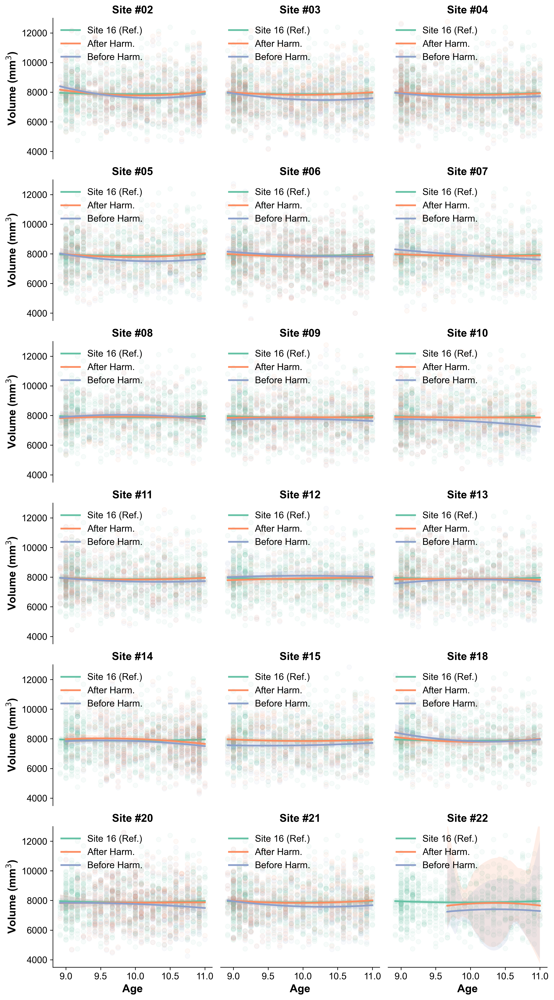

In [95]:
# Plot the harmonized data in subplots against the site16 data (x=age, y=smri).
fig, axes = plt.subplots(6, 3, figsize=(10, 18), dpi=300)

cmap = sns.color_palette("Set2", 8)

for i, site in enumerate(site_list):
    # Get the data for the site.
    site_data = abcd_harmonized_vol_df[abcd_harmonized_vol_df["site"] == site]

    # Get data before the harmonization.
    site_data_prior = abcd_harmonization_vol_df[abcd_harmonization_vol_df["site"] == site]

    # Get the data for the site16.
    site16_data = abcd_harmonized_vol_df[abcd_harmonized_vol_df["site"] == "site16"]

    # We will use regions IPL_L_6_2 for the plots.
    region = "IPL_L_6_2"
    region_data = site_data[site_data["bundle"] == region]
    region16_data = site16_data[site16_data["bundle"] == region]
    region_data_prior = site_data_prior[site_data_prior["bundle"] == region]

    # Plot the data.
    # Extract the current axis.
    ax = axes.flatten()[i]
    sns.regplot(data=region16_data, x="age", y="mean", ax=ax,
                color=cmap[0], scatter=True, ci=95, order=2,
                line_kws={"label": "Site 16 (Ref.)"},
                scatter_kws={"zorder": 0, "alpha": 0.05})
    sns.regplot(data=region_data, x="age", y="mean", ax=ax,
                color=cmap[1], scatter=True, ci=95, order=2,
                line_kws={"label": "After Harm."},
                scatter_kws={"zorder": 2, "alpha": 0.05})
    sns.regplot(data=region_data_prior, x="age", y="mean", ax=ax,
                color=cmap[2], scatter=True, ci=95, order=2,
                line_kws={"label": "Before Harm."},
                scatter_kws={"zorder": 1, "alpha": 0.05})
    
    # Set legend.
    ax.legend(loc="upper left", fontsize=12, frameon=False)

    site_lab = site.replace("site", "Site #")
    ax.set_title(f"{site_lab}", fontdict={"fontsize": 14, "weight": "bold"})
    #ax.set_xlim(105, 135)
    ax.set_ylim(3500, 13000)

    if i // 3 == 5:
        ax.set_xlabel("Age", fontdict={"fontsize": 14, "weight": "bold"})
        ax.spines[["top", "right"]].set_visible(False)
    else:
        axes[i // 3, i % 3].set_xticklabels([])
        axes[i // 3, i % 3].set_xticks([])
        axes[i // 3, i % 3].set_xlabel("")
        axes[i // 3, i % 3].spines[["top", "right", "bottom"]].set_visible(False)

    if i % 3 == 0:
        ax.set_ylabel("Volume (mm$^3$)", fontdict={"fontsize": 14, "weight": "bold"})
    else:
        axes[i // 3, i % 3].set_yticklabels([])
        axes[i // 3, i % 3].set_yticks([])
        axes[i // 3, i % 3].set_ylabel("")
        axes[i // 3, i % 3].spines[["top", "right", "left"]].set_visible(False)

# Make only left and bottom axes show ticks.
for ax in axes.flatten():
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()
plt.savefig(f"{output_folder}/Harmonization/ABCD_harmonization_vol.png", dpi=300)

In [89]:
# Function to reformat back the harmonized data into a features per column and subjects per row.
def reformat_harmonized_data(harmonized_df, nb_regions=227):
    """
    Reformat the harmonized data into a features per column and subjects per row.
    """
    # Fetch bundle list.
    bundles = harmonized_df["bundle"].unique()

    # Create a list of list to store the data.
    records = []

    # Loop over each subject.
    for s, sub in enumerate(tqdm(harmonized_df["sid"].unique(), desc="Reformatting harmonized data")):
        # Get the data for the subject.
        sub_data = harmonized_df[harmonized_df["sid"] == sub]
        assert len(sub_data) == nb_regions, f"Subject {sub} has {len(sub_data)} regions, expected {nb_regions}."

        # Get the demographic data for the subject.
        site = sub_data["site"].values[0]
        age = sub_data["age"].values[0]
        handedness = sub_data["handedness"].values[0]

        data = []
        for bundle in bundles:
            # Get the data for the bundle.
            data.append(sub_data[sub_data["bundle"] == bundle]["mean"].values[0])
        
        # Append the data to the records.
        records.append([sub, site, age, handedness] + data)
    
    # Create a dataframe from the records.
    columns = ["sid", "site", "age", "handedness"] + bundles.tolist()
    reformatted_df = pd.DataFrame(records, columns=columns)
    reformatted_df.set_index("sid", inplace=True)

    return reformatted_df



In [ ]:
reformatted_df = reformat_harmonized_data(abcd_harmonized_vol_df)

# Using the atlas tsv, get the column order.
col_order = atlas["label"].tolist()

# reorder the columns of the reformatted df.
reformatted_df = reformatted_df[col_order]

Reformatting harmonized data: 100%|██████████| 7709/7709 [11:33<00:00, 11.12it/s]


In [105]:
# Do some random sanity checks to make sure the reformatting was done correctly.
radn_subs = np.random.choice(reformatted_df.index.unique(), 50)
radn_conns = np.random.choice(reformatted_df.columns[3:].unique(), 5)

for s in tqdm(radn_subs, desc="Performing sanity checks on random subjects"):
    for c in radn_conns:

        sub_data = abcd_harmonized_vol_df[abcd_harmonized_vol_df["sid"] == s]
        # Get the data for the subject.
        sub_data = sub_data[sub_data["bundle"] == c]["mean"].values
        # Assert the data for each subject and connection is identical to the original data.
        assert reformatted_df.loc[s, c] == sub_data, f"Data for subject {s} and connection {c} do not match. ({reformatted_df.loc[s, c]} != {sub_data})"

Performing sanity checks on random subjects: 100%|██████████| 50/50 [00:17<00:00,  2.93it/s]


In [106]:
# Saving the reformatted data.
reformatted_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_vol_reformatted.csv", index=True)

In [107]:
# Load back up the harmonized data, and stack them vertically (for thickness).
abcd_harmonized_thickness_df = pd.DataFrame()
for site in tqdm(abcd_harmonization_thickness_df["site"].unique(), desc="Loading harmonized data"):
    if site == "site16":
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Thickness/ABCD_harmonization_thickness_site16.csv")
    else:
        # Load the harmonized data.
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Thickness/{site}.thickness.clinical.harmonized.csv.gz", compression="gzip")
    
    # Append the data to the harmonized dataframe.
    abcd_harmonized_thickness_df = pd.concat([abcd_harmonized_thickness_df, site_harm], axis=0)

# Save the harmonized data.
abcd_harmonized_thickness_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_thickness.csv", index=False)

Loading harmonized data: 100%|██████████| 19/19 [00:02<00:00,  7.43it/s]


/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:

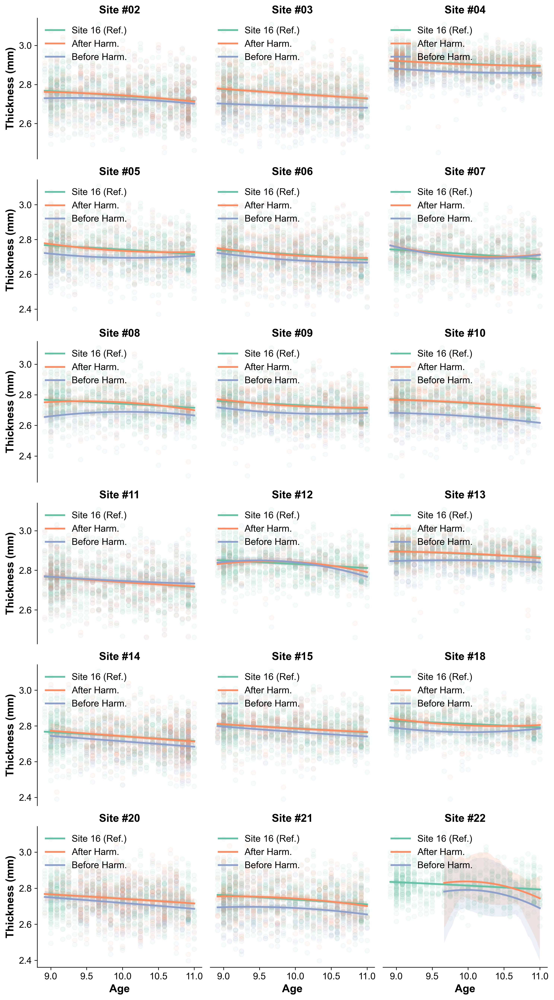

In [109]:
# Plot the harmonized data in subplots against the site16 data (x=age, y=smri).
fig, axes = plt.subplots(6, 3, figsize=(10, 18), dpi=300)

cmap = sns.color_palette("Set2", 8)

for i, site in enumerate(site_list):
    # Get the data for the site.
    site_data = abcd_harmonized_thickness_df[abcd_harmonized_thickness_df["site"] == site]

    # Get data before the harmonization.
    site_data_prior = abcd_harmonization_thickness_df[abcd_harmonization_thickness_df["site"] == site]

    # Get the data for the site16.
    site16_data = abcd_harmonized_thickness_df[abcd_harmonized_thickness_df["site"] == "site16"]

    # We will use regions IPL_L_6_2 for the plots.
    region = "IPL_L_6_2"
    region_data = site_data[site_data["bundle"] == region]
    region16_data = site16_data[site16_data["bundle"] == region]
    region_data_prior = site_data_prior[site_data_prior["bundle"] == region]

    # Plot the data.
    # Extract the current axis.
    ax = axes.flatten()[i]
    sns.regplot(data=region16_data, x="age", y="mean", ax=ax,
                color=cmap[0], scatter=True, ci=95, order=2,
                line_kws={"label": "Site 16 (Ref.)"},
                scatter_kws={"zorder": 0, "alpha": 0.05})
    sns.regplot(data=region_data, x="age", y="mean", ax=ax,
                color=cmap[1], scatter=True, ci=95, order=2,
                line_kws={"label": "After Harm."},
                scatter_kws={"zorder": 2, "alpha": 0.05})
    sns.regplot(data=region_data_prior, x="age", y="mean", ax=ax,
                color=cmap[2], scatter=True, ci=95, order=2,
                line_kws={"label": "Before Harm."},
                scatter_kws={"zorder": 1, "alpha": 0.05})
    
    # Set legend.
    ax.legend(loc="upper left", fontsize=12, frameon=False)

    site_lab = site.replace("site", "Site #")
    ax.set_title(f"{site_lab}", fontdict={"fontsize": 14, "weight": "bold"})
    #ax.set_xlim(105, 135)
    #ax.set_ylim(3500, 13000)

    if i // 3 == 5:
        ax.set_xlabel("Age", fontdict={"fontsize": 14, "weight": "bold"})
        ax.spines[["top", "right"]].set_visible(False)
    else:
        axes[i // 3, i % 3].set_xticklabels([])
        axes[i // 3, i % 3].set_xticks([])
        axes[i // 3, i % 3].set_xlabel("")
        axes[i // 3, i % 3].spines[["top", "right", "bottom"]].set_visible(False)

    if i % 3 == 0:
        ax.set_ylabel("Thickness (mm)", fontdict={"fontsize": 14, "weight": "bold"})
    else:
        axes[i // 3, i % 3].set_yticklabels([])
        axes[i // 3, i % 3].set_yticks([])
        axes[i // 3, i % 3].set_ylabel("")
        axes[i // 3, i % 3].spines[["top", "right", "left"]].set_visible(False)

# Make only left and bottom axes show ticks.
for ax in axes.flatten():
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()
plt.savefig(f"{output_folder}/Harmonization/ABCD_harmonization_thickness.png", dpi=300)

In [ ]:
reformatted_thickness_df = reformat_harmonized_data(abcd_harmonized_thickness_df, 188)

# Using the atlas tsv, get the column order.
col_order = atlas["label"].tolist()
col_order = col_order[:188]

# reorder the columns of the reformatted df.
reformatted_thickness_df = reformatted_thickness_df[col_order]

Reformatting harmonized data: 100%|██████████| 7709/7709 [09:31<00:00, 13.48it/s]


In [126]:
# Sanity checks.
radn_subs = np.random.choice(reformatted_thickness_df.index.unique(), 50)
radn_conns = np.random.choice(reformatted_thickness_df.columns[3:].unique(), 5)

for s in tqdm(radn_subs, desc="Performing sanity checks on random subjects"):
    for c in radn_conns:

        sub_data = abcd_harmonized_thickness_df[abcd_harmonized_thickness_df["sid"] == s]
        # Get the data for the subject.
        sub_data = sub_data[sub_data["bundle"] == c]["mean"].values
        # Assert the data for each subject and connection is identical to the original data.
        assert reformatted_thickness_df.loc[s, c] == sub_data, f"Data for subject {s} and connection {c} do not match."

Performing sanity checks on random subjects: 100%|██████████| 50/50 [00:14<00:00,  3.40it/s]


In [127]:
# Export the reformatted data.
reformatted_thickness_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_thickness_reformatted.csv", index=True)

In [117]:
# Loading back up the harmonized data, and stack them vertically (for area).
abcd_harmonized_area_df = pd.DataFrame()

for site in tqdm(abcd_harmonization_area_df["site"].unique(), desc="Loading harmonized data"):
    if site == "site16":
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Area/ABCD_harmonization_area_site16.csv")
    else:
        # Load the harmonized data.
        site_harm = pd.read_csv(f"{output_folder}/Harmonization/Area/{site}.area.clinical.harmonized.csv.gz", compression="gzip")
    
    # Append the data to the harmonized dataframe.
    abcd_harmonized_area_df = pd.concat([abcd_harmonized_area_df, site_harm], axis=0)

# Save the harmonized data.
abcd_harmonized_area_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_area.csv", index=False)

Loading harmonized data:   0%|          | 0/19 [00:00<?, ?it/s]

Loading harmonized data: 100%|██████████| 19/19 [00:02<00:00,  8.01it/s]


/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:261: RankWarning: Polyfit may be poorly conditioned
  return np.polyval(np.polyfit(_x, _y, order), grid)
/Users/anthonygagnon/code/Gagnon_BrainProfilesAssociations/.venv/lib/python3.12/site-packages/seaborn/regression.py:

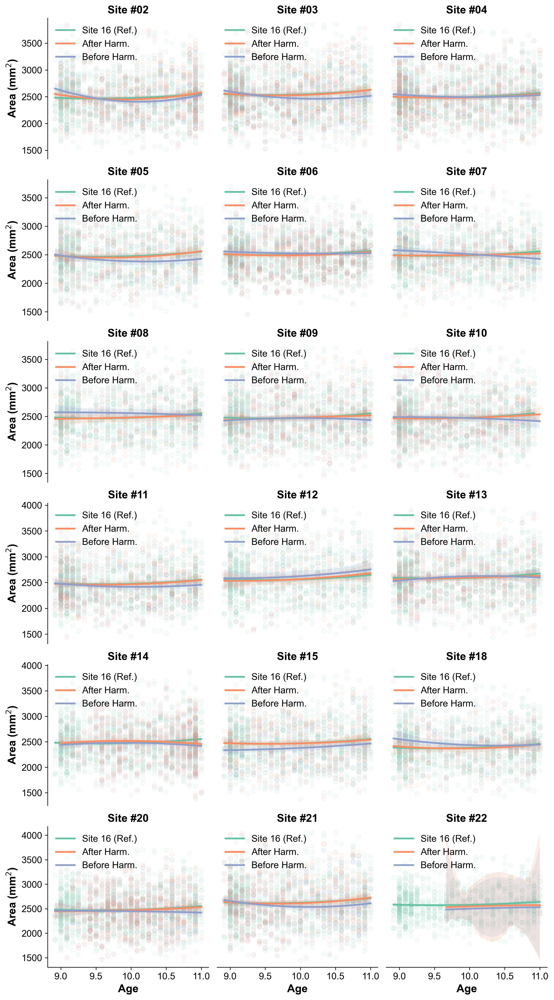

In [118]:
# Plot the harmonized data in subplots against the site16 data (x=age, y=smri).
fig, axes = plt.subplots(6, 3, figsize=(10, 18), dpi=300)

cmap = sns.color_palette("Set2", 8)

for i, site in enumerate(site_list):
    # Get the data for the site.
    site_data = abcd_harmonized_area_df[abcd_harmonized_area_df["site"] == site]

    # Get data before the harmonization.
    site_data_prior = abcd_harmonization_area_df[abcd_harmonization_area_df["site"] == site]

    # Get the data for the site16.
    site16_data = abcd_harmonized_area_df[abcd_harmonized_area_df["site"] == "site16"]

    # We will use regions IPL_L_6_2 for the plots.
    region = "IPL_L_6_2"
    region_data = site_data[site_data["bundle"] == region]
    region16_data = site16_data[site16_data["bundle"] == region]
    region_data_prior = site_data_prior[site_data_prior["bundle"] == region]

    # Plot the data.
    # Extract the current axis.
    ax = axes.flatten()[i]
    sns.regplot(data=region16_data, x="age", y="mean", ax=ax,
                color=cmap[0], scatter=True, ci=95, order=2,
                line_kws={"label": "Site 16 (Ref.)"},
                scatter_kws={"zorder": 0, "alpha": 0.05})
    sns.regplot(data=region_data, x="age", y="mean", ax=ax,
                color=cmap[1], scatter=True, ci=95, order=2,
                line_kws={"label": "After Harm."},
                scatter_kws={"zorder": 2, "alpha": 0.05})
    sns.regplot(data=region_data_prior, x="age", y="mean", ax=ax,
                color=cmap[2], scatter=True, ci=95, order=2,
                line_kws={"label": "Before Harm."},
                scatter_kws={"zorder": 1, "alpha": 0.05})
    
    # Set legend.
    ax.legend(loc="upper left", fontsize=12, frameon=False)

    site_lab = site.replace("site", "Site #")
    ax.set_title(f"{site_lab}", fontdict={"fontsize": 14, "weight": "bold"})
    #ax.set_xlim(105, 135)
    #ax.set_ylim(3500, 13000)

    if i // 3 == 5:
        ax.set_xlabel("Age", fontdict={"fontsize": 14, "weight": "bold"})
        ax.spines[["top", "right"]].set_visible(False)
    else:
        axes[i // 3, i % 3].set_xticklabels([])
        axes[i // 3, i % 3].set_xticks([])
        axes[i // 3, i % 3].set_xlabel("")
        axes[i // 3, i % 3].spines[["top", "right", "bottom"]].set_visible(False)

    if i % 3 == 0:
        ax.set_ylabel("Area (mm$^2$)", fontdict={"fontsize": 14, "weight": "bold"})
    else:
        axes[i // 3, i % 3].set_yticklabels([])
        axes[i // 3, i % 3].set_yticks([])
        axes[i // 3, i % 3].set_ylabel("")
        axes[i // 3, i % 3].spines[["top", "right", "left"]].set_visible(False)

# Make only left and bottom axes show ticks.
for ax in axes.flatten():
    ax.xaxis.set_ticks_position("bottom")
    ax.yaxis.set_ticks_position("left")
    ax.tick_params(axis="both", labelsize=12)

plt.tight_layout()
plt.savefig(f"{output_folder}/Harmonization/ABCD_harmonization_area.png", dpi=300)

In [ ]:
reformatted_area_df = reformat_harmonized_data(abcd_harmonized_area_df, 188)

# Using the atlas tsv, get the column order.
col_order = atlas["label"].tolist()
col_order = col_order[:188]

# reorder the columns of the reformatted df.
reformatted_area_df = reformatted_area_df[col_order]

Reformatting harmonized data: 100%|██████████| 7709/7709 [09:30<00:00, 13.51it/s]


In [123]:
# Sanity checks.
radn_subs = np.random.choice(reformatted_thickness_df.index.unique(), 50)
radn_conns = np.random.choice(reformatted_thickness_df.columns[3:].unique(), 5)

for s in tqdm(radn_subs, desc="Performing sanity checks on random subjects"):
    for c in radn_conns:

        sub_data = abcd_harmonized_area_df[abcd_harmonized_area_df["sid"] == s]
        # Get the data for the subject.
        sub_data = sub_data[sub_data["bundle"] == c]["mean"].values
        # Assert the data for each subject and connection is identical to the original data.
        assert reformatted_area_df.loc[s, c] == sub_data, f"Data for subject {s} and connection {c} do not match."

Performing sanity checks on random subjects: 100%|██████████| 50/50 [00:15<00:00,  3.21it/s]


In [124]:
# Export the reformatted data.
reformatted_area_df.to_csv(f"{output_folder}/Harmonization/ABCD_harmonized_area_reformatted.csv", index=True)

### **Harmonizing resting-state fMRI data across ABCD sites**

The following cells will harmonize the resting-state functional connectivity data using `fc-covbat` [1].
As opposed to clinical-comBAT, `fc-covbat` does not use a reference site, but rather harmonize all sites into
a common space. However, it leverages information from all connections to find the different site mappings.

**Since the ABCD dataset used here contains more than 7,000 subjects, running the R script (`scripts/fc_covbat.R`)
will consume a lot of memory. It is therefore recommended to run the following command on a system with more than
16GB of RAM. The current study ran the script on an HPC server with 64GB of RAM. Execution took roughly 10 minutes.**

**References**

[1] Chen, A. A., Srinivasan, D., Pomponio, R., Fan, Y., Nasrallah, I. M., Resnick, S. M., Beason-Held, L. L., Davatzikos, C., Satterthwaite, T. D., Bassett, D. S., Shinohara, R. T., & Shou, H. (2022). Harmonizing functional connectivity reduces scanner effects in community detection. NeuroImage, 256, 119198. https://doi.org/10.1016/j.neuroimage.2022.119198


In [ ]:
# **Run this on a system with more than 16GB of RAM.**
!Rscript {repository_dir}/scripts/fc_covbat.R \
    --mats {data_abcd}/FunctionalConnectivityNumpy/ \
    --demo {output_folder}/abcd_demo.csv \
    --out {output_folder}/Harmonization/RSFCHarmonized/

In [ ]:
# Let's compute a t-SNE for each subject's FC matrices (before and after harmonization) to visualize the data.
from sklearn.manifold import TSNE

# Load the demo data
demo_df = pd.read_csv(f"{output_folder}/abcd_demo.csv")

l_mat_harm = []

# To avoid memory issues, we will load the FC matrices for individual subjects, compute the t-SNE, them remove the mat.
for s in tqdm(demo_df["subjectkey"].unique(), desc="Computing t-SNE for each subject"):
    # Load the matrices
    f_harm = pathlib.Path(f"{output_folder}/Harmonization/RSFCHarmonized/").glob(f"{s}*").__next__()
    mat_harm = np.load(f_harm.resolve())
    l_mat_harm.append(mat_harm.ravel())

# Compute the t-SNE.
tsne_harm = TSNE(n_components=2, random_state=42).fit_transform(np.array(l_mat_harm))

demo_df.loc[:, "tsne_harm_PC1"] = tsne_harm[:, 0]
demo_df.loc[:, "tsne_harm_PC2"] = tsne_harm[:, 1]

# delete the matrices from memory.
del l_mat_harm

Computing t-SNE for each subject: 100%|██████████| 7709/7709 [05:51<00:00, 21.92it/s]


In [22]:
l_mat_raw = []

# To avoid memory issues, we will load the FC matrices for individual subjects, compute the t-SNE, them remove the mat.
for s in tqdm(demo_df["subjectkey"].unique(), desc="Computing t-SNE for each subject"):
    # Load the matrices
    f_raw = pathlib.Path(f"{data_abcd}/FunctionalConnectivityNumpy/").glob(f"{s}*").__next__()
    mat_raw = np.load(f_raw.resolve())
    l_mat_raw.append(mat_raw.ravel())

# Compute the t-SNE.
tsne_raw = TSNE(n_components=2, random_state=42).fit_transform(np.array(l_mat_raw))

demo_df.loc[:, "tsne_raw_PC1"] = tsne_raw[:, 0]
demo_df.loc[:, "tsne_raw_PC2"] = tsne_raw[:, 1]

# delete the matrices from memory.
del l_mat_raw

Computing t-SNE for each subject: 100%|██████████| 7709/7709 [07:45<00:00, 16.57it/s]


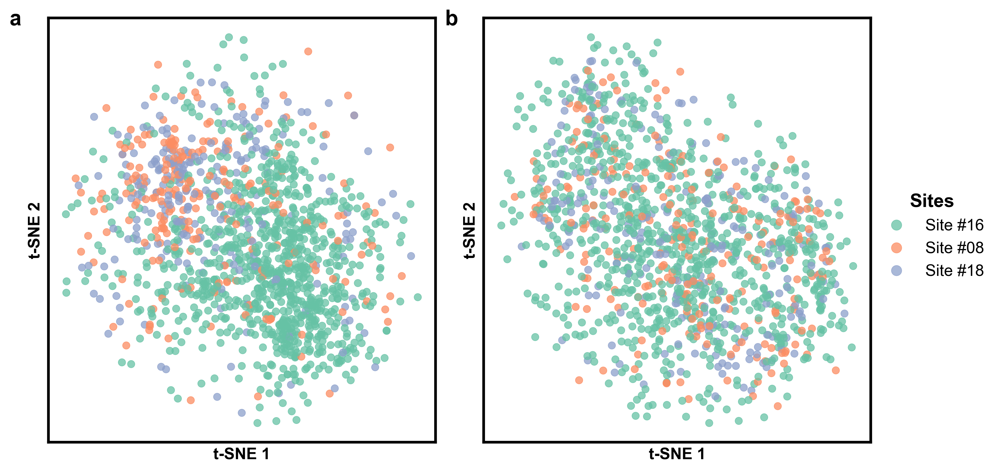

In [80]:
# Plot the t-SNE.
fig, ax = plt.subplots(1, 2, figsize=(10, 5), dpi=300)

sites = ["site16", "site18", "site08"]
viz_df = demo_df[demo_df["site_id"].isin(sites)]

sns.scatterplot(data=viz_df, x="tsne_raw_PC1", y="tsne_raw_PC2", hue="site_id", ax=ax[0], s=30,
                alpha=0.75, palette="Set2", edgecolor=None)
sns.scatterplot(data=viz_df, x="tsne_harm_PC1", y="tsne_harm_PC2", hue="site_id", ax=ax[1], s=30,
                alpha=0.75, palette="Set2", edgecolor=None, legend=False)

for axe in ax:
    axe.spines[["top", "bottom", "right", "left"]].set_linewidth(2)
    axe.set_xlabel("t-SNE 1", fontdict={"weight": "bold", "size": 12})
    axe.set_ylabel("t-SNE 2", fontdict={"weight": "bold", "size": 12})
    axe.set_xticks([])
    axe.set_yticks([])

# Add a, b letters to the top left of each panel.
ax[0].text(-0.1, 1.02, "a", transform=ax[0].transAxes, fontsize=16, fontweight="bold",
           ha="left", va="top")
ax[1].text(-0.1, 1.02, "b", transform=ax[1].transAxes, fontsize=16, fontweight="bold",
           ha="left", va="top")

# Shared legend to the right of both panels. legend=False drops the handles,
# so the first panel keeps its legend long enough to copy them out.
handles, labels = ax[0].get_legend_handles_labels()
ax[0].get_legend().remove()
fig.legend(
    handles,
    [lab.replace("site", "Site #") for lab in labels],
    loc="center left",
    bbox_to_anchor=(0.9, 0.5),
    frameon=False,
    fontsize=12,
    markerscale=1.4,
    title="Sites",
    title_fontproperties={"weight": "bold", "size": 14},
)
fig.tight_layout(rect=(0, 0, 0.92, 1))
plt.savefig(f"{output_folder}/Harmonization/ABCD_t-SNE_rsfc_harmonization.png", dpi=300, bbox_inches="tight")
